# Домашнее задание 5. Факторная обеспеченность, торговля и гипотезы о рынке

**Оценивание.** `Неделя 5_НС_Поиск экспортных рынков_ДЗ.ipynb` весит 50% оценки. PDF-отчёт также весит 50% оценки. Максимальный балл за домашнее задание составляет 10 баллов.
**Пояснение к разбалловке.** В предмете нет официального деления на уровни сложности. Цвета лишь помогают ориентироваться в заданиях. За все пункты синего уровня можно получить максимум 5 баллов из 10. Пункты синего и красного уровней дают максимум 7 баллов из 10. Пункты всех трёх уровней дают максимум 10 баллов из 10. Максимальный балл за домашнее задание составляет 10 баллов. Бонусный пункт 3г даёт 1 дополнительный балл чёрного уровня, но итоговый балл за домашнее задание всё равно не может превышать 10.

В этом блокноте ты выполняешь только техническую часть. Загрузи данные, рассчитай показатели, собери таблицы и построй графики. Интерпретацию, аргументы и итоговые выводы пиши в PDF-отчёте, ссылаясь на результаты этого блокнота.

Во всех прикладных пунктах используй российский экспортный товар, который твоя команда выбрала на неделе 3. Товар для сравнения нужен только для расчёта относительной структуры экспорта. Не подменяй товар своей команды широкой отраслью или разделом HS.

## Для работы тебе пригодятся

Лонгрид недели 5 нужен как справочник по факторной обеспеченности, факторной интенсивности и теоремам Хекшера — Олина и Рыбчинского. Семинар поможет перейти от теории к вычислениям и покажет, как осторожно сопоставлять факторные показатели с торговыми данными.

Готовый `w5_loader.py` только загружает и очищает данные. В первой кодовой ячейке заполни паспорт товара, товара для сравнения, фактора и стран. Показатели $RX$, $NEX$, темпы роста и группировки рассчитай самостоятельно. Не редактируй и не сдавай загрузчик.

Не смешивай два понятия. Факторная ёмкость описывает товар: насколько много земли, труда или капитала нужно для его производства. Факторная обеспеченность описывает страну: сколько этого фактора приходится на человека или работника.

Аналитическую часть оформи в LaTeX и сдай PDF-отчёт, полученный после компиляции. Вместе с ним сдай заполненный блокнот `.ipynb`; исходный `.tex` сдавать не нужно.


In [1]:
# Запусти эту ячейку перед выполнением заданий.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

pd.options.display.float_format = "{:,.3f}".format

# Файла w5_loader.py в задании не оказалось, поэтому три функции загрузки написаны здесь.
# Названия и смысл те же, что в шаблоне: торговля берётся из BACI через API OEC,
# показатели стран — из World Bank WDI.
OEC_URL = "https://api-v2.oec.world/tesseract"
OEC_CUBE = "trade_i_baci_a_17"  # BACI в классификации HS 2017, годы 2018–2024
WDI_URL = "https://api.worldbank.org/v2/country/all/indicator"


def load_oec_members(level, search):
    """Ищет код товара в OEC по английскому названию."""
    params = {"cube": OEC_CUBE, "level": level, "search": search, "limit": "20,0"}
    response = requests.get(f"{OEC_URL}/members.jsonrecords", params=params, timeout=120)
    response.raise_for_status()
    return pd.DataFrame(response.json()["members"])


def load_country_trade(product_key, level="HS4"):
    """Экспорт и импорт товара по всем странам и годам, доллары США."""
    flows = []
    for side, column in [("Exporter", "export"), ("Importer", "import")]:
        params = {
            "cube": OEC_CUBE,
            "drilldowns": f"Year,{side} Country Official",
            "measures": "Trade Value",
            "include": f"{level} Official:{product_key}",
            "locale": "en",
        }
        response = requests.get(f"{OEC_URL}/data.jsonrecords", params=params, timeout=300)
        response.raise_for_status()
        part = pd.DataFrame(response.json()["data"])
        part = part.rename(columns={
            "Year": "year",
            f"{side} Country Official ID": "iso3",
            f"{side} Country Official": "country",
            "Trade Value": column,
        })
        part["iso3"] = part["iso3"].str.upper()
        flows.append(part)

    exports_part = flows[0]
    imports_part = flows[1].drop(columns="country")
    trade = exports_part.merge(imports_part, on=["year", "iso3"], how="outer")
    # страна могла только импортировать товар, тогда названия нет в таблице экспорта
    names = pd.concat([flows[0][["iso3", "country"]], flows[1][["iso3", "country"]]]).drop_duplicates("iso3")
    trade = trade.drop(columns="country").merge(names, on="iso3", how="left")
    trade[["export", "import"]] = trade[["export", "import"]].fillna(0)
    return trade.sort_values(["iso3", "year"]).reset_index(drop=True)


def load_wdi(indicator, start, end):
    """Показатель World Bank WDI по всем странам за годы start–end."""
    params = {"date": f"{start}:{end}", "format": "json", "per_page": 20000}
    response = requests.get(f"{WDI_URL}/{indicator}", params=params, timeout=120)
    response.raise_for_status()
    rows = response.json()[1]
    wdi = pd.DataFrame({
        "iso3": [row["countryiso3code"] for row in rows],
        "country": [row["country"]["value"] for row in rows],
        "year": [int(row["date"]) for row in rows],
        "value": [row["value"] for row in rows],
    })
    return wdi.dropna(subset=["value"])


# Паспорт. Товар команды с недели 3 — фанера, группа 4412 целиком.
PRODUCT_NAME_RU = "Фанера, фанерованные панели и аналогичная слоистая древесина"
PRODUCT_NAME_EN = "Plywood, veneered panels and similar laminated wood"
PRODUCT_CODE = "4412"
PRODUCT_LEVEL = "HS4"
PRODUCT_KEY = "4412"  # нашли через load_oec_members, см. вывод ниже
COMPARISON_PRODUCT_NAME = "Лекарства в дозированном виде и в упаковках для продажи (Packaged Medicaments)"
COMPARISON_PRODUCT_KEY = "3004"
FACTOR_NAME = "Площадь лесов на одного жителя, га на человека"
FACTOR_INDICATOR = "AG.LND.FRST.K2"  # площадь лесов, кв. км
POPULATION_INDICATOR = "SP.POP.TOTL"  # население, чтобы перейти к расчёту на человека
COMPARISON_ISO = ["RUS", "CHN"]
SAMPLE_ISO = [
    "RUS",
    # крупные экспортёры фанеры
    "CHN", "IDN", "VNM", "BRA", "FIN", "MYS", "LVA", "CHL",
    # крупные импортёры фанеры
    "USA", "JPN", "DEU", "KOR", "GBR", "EGY", "IND", "SAU",
]
MARKET_ISO = ["USA", "JPN", "KOR", "IND", "SAU", "EGY"]

display(load_oec_members("HS4 Official", "plywood"))
display(load_oec_members("HS4 Official", "medicaments"))

print(f"Товар p: {PRODUCT_NAME_RU} ({PRODUCT_NAME_EN}), {PRODUCT_LEVEL} {PRODUCT_CODE}, HS 2017")
print(f"Товар q: {COMPARISON_PRODUCT_NAME}, HS4 {COMPARISON_PRODUCT_KEY}, HS 2017")
print(f"Фактор: {FACTOR_NAME} ({FACTOR_INDICATOR} / {POPULATION_INDICATOR}, World Bank WDI)")
print(f"Пара стран: {COMPARISON_ISO}, выборка: {len(SAMPLE_ISO)} стран, рынки: {MARKET_ISO}")

,key,caption
0,4412,Plywood


,key,caption
0,3003,Unpackaged Medicaments
1,3004,Packaged Medicaments


Товар p: Фанера, фанерованные панели и аналогичная слоистая древесина (Plywood, veneered panels and similar laminated wood), HS4 4412, HS 2017
Товар q: Лекарства в дозированном виде и в упаковках для продажи (Packaged Medicaments), HS4 3004, HS 2017
Фактор: Площадь лесов на одного жителя, га на человека (AG.LND.FRST.K2 / SP.POP.TOTL, World Bank WDI)
Пара стран: ['RUS', 'CHN'], выборка: 17 стран, рынки: ['USA', 'JPN', 'KOR', 'IND', 'SAU', 'EGY']


Почему так. Фанера — продукт переработки древесины, а древесина растёт на лесной земле, поэтому в логике Хекшера — Олина берём фактор «земля», а точнее лесную землю. Сам лес как сырьё фактором не считаем, считаем землю, на которой он растёт. Для сравнения нужен товар, который почти не использует лес: лекарства (HS 3004) держатся на человеческом капитале и оборудовании. Оба кода — уровень HS4 в версии HS 2017.

## **[Синий, 3 балла]** Техническое задание 1. Факторная обеспеченность и структура экспорта

### **[Синий, 1 балл]** Пункт 1а. Факторная обеспеченность двух стран

В первой кодовой ячейке укажи две страны и код показателя WDI, который приближённо описывает выбранный фактор. Загрузи данные вызовом `load_wdi(FACTOR_INDICATOR, 2020, 2024)`. Последнее доступное наблюдение по каждой стране сохрани в `factor_latest`, а строки двух выбранных стран — в `factor_pair`.

Пусть $f_i$ — значение факторного показателя в стране $i$. Рассчитай отношение $f_A/f_B$, где $A$ — первая страна в `COMPARISON_ISO`, а $B$ — вторая. Для отбора последних наблюдений используй `sort_values()` и `drop_duplicates()`, а для выбора стран — `isin()`.

**Исследовательский смысл.** Отношение $f_A/f_B$ сравнивает обеспеченность стран одним фактором. Оно не измеряет факторную ёмкость товара и не доказывает, что различие в торговле вызвано только этим фактором.

**Что получить на выходе.** таблицу `factor_pair` с двумя странами, годами и значениями показателя, а также одно отношение $f_A/f_B$. В письменной части объясни выбор фактора, его единицы и связь с производством товара.

**Пример вывода.**

| ISO3 | страна | фактор | год фактора |
|---|---|---:|---:|
| [страна A] | [название] | [значение] | [год] |
| [страна B] | [название] | [значение] | [год] |

```text
Отношение факторов f_A / f_B: [значение]
```

In [2]:
# Показатель WDI даёт общую площадь лесов. Страны разного размера так сравнивать нельзя,
# поэтому делим площадь на население и получаем гектары леса на одного жителя.
forest = load_wdi(FACTOR_INDICATOR, 2020, 2024)
population = load_wdi(POPULATION_INDICATOR, 2020, 2024)

factor = forest.merge(population[["iso3", "year", "value"]], on=["iso3", "year"],
                      suffixes=("_forest_km2", "_population"))
factor["factor"] = factor["value_forest_km2"] * 100 / factor["value_population"]  # 1 кв. км = 100 га

# Для каждой страны оставляем последний год, за который есть оба числа
factor_latest = factor.sort_values("year").drop_duplicates("iso3", keep="last")
factor_latest = factor_latest.rename(columns={"year": "factor_year"})
factor_latest = factor_latest[["iso3", "country", "factor", "factor_year"]]

factor_pair = factor_latest[factor_latest["iso3"].isin(COMPARISON_ISO)]
factor_pair = factor_pair.set_index("iso3").loc[COMPARISON_ISO].reset_index()
display(factor_pair)

f_a = factor_pair.loc[0, "factor"]
f_b = factor_pair.loc[1, "factor"]
print(f"Отношение факторов f_A / f_B ({COMPARISON_ISO[0]} / {COMPARISON_ISO[1]}): {f_a / f_b:.1f}")
print()

# Факторная ёмкость — свойство товара, а не страны. Гектаров леса на доллар экспорта
# никто не публикует, поэтому берём ближайший измеримый показатель: сколько круглого леса
# уходит на 1 куб. м фанеры. Это лишь приближение к затратам лесной земли.
intensity = pd.DataFrame({
    "товар": [f"p: фанера, HS {PRODUCT_CODE}", f"q: лекарства, HS {COMPARISON_PRODUCT_KEY}"],
    "расход древесины": ["2,3–2,4 куб. м круглого леса на 1 куб. м фанеры", "древесина не используется"],
    "на что опирается производство": [
        "лесная земля, труд на заготовке и лущении, линии и прессы",
        "человеческий капитал (разработка, контроль качества), оборудование",
    ],
    "источник": [
        "FAO, ITTO, UNECE (2020), табл. 5.4: лиственная фанера в Европе, среднее 2,29, медиана 2,40",
        "описание технологии, числовой оценки по лесу нет",
    ],
})
pd.set_option("display.max_colwidth", 120)
display(intensity)

,iso3,country,factor,factor_year
0,RUS,Russian Federation,5.790,2024
1,CHN,China,0.160,2024


Отношение факторов f_A / f_B (RUS / CHN): 36.2



,товар,расход древесины,на что опирается производство,источник
0,"p: фанера, HS 4412","2,3–2,4 куб. м круглого леса на 1 куб. м фанеры","лесная земля, труд на заготовке и лущении, линии и прессы","FAO, ITTO, UNECE (2020), табл. 5.4: лиственная фанера в Европе, среднее 2,29, медиана 2,40"
1,"q: лекарства, HS 3004",древесина не используется,"человеческий капитал (разработка, контроль качества), оборудование","описание технологии, числовой оценки по лесу нет"


**Что видим.** Леса на одного жителя в России в десятки раз больше, чем в Китае (точное отношение — в выводе выше). Это характеристика стран. Характеристика товаров — во второй таблице: на кубометр фанеры уходит больше двух кубометров леса, а лекарствам лес не нужен вообще. Значит, по лесной земле фанера заметно интенсивнее, чем лекарства.

### **[Синий, 1 балл]** Пункт 1б. Относительная структура экспорта

Загрузи торговлю товаром $p$ и товаром $q$ с помощью `load_country_trade()`. Здесь $p$ — товар твоей команды, а $q$ — товар для сравнения. Оставь две выбранные страны и соедини таблицы по году и коду ISO3 методом `merge()`. Затем самостоятельно рассчитай

$$
RX_i=\frac{X_{i,p}}{X_{i,q}},
$$

где $X_{i,p}$ и $X_{i,q}$ — экспорт двух товаров из страны $i$. Показатель $RX_i$ отвечает на вопрос, насколько велик экспорт товара команды по отношению к экспорту товара для сравнения. Для последнего общего года выведи $X_{i,p}$, $X_{i,q}$ и $RX_i$ по обеим странам.

**Исследовательский смысл.** $RX_i$ описывает относительную структуру экспорта, а не размер экономики и не производительность отрасли. Сопоставление порядка стран по $f_i$ и $RX_i$ даёт простую проверку факторной гипотезы, но не устанавливает причинную связь.

**Что получить на выходе.** таблицу двух стран за последний общий год с экспортом обоих товаров и рассчитанным $RX_i$.

**Пример вывода.**

| ISO3 | $X_{i,p}$ | $X_{i,q}$ | $RX_i$ |
|---|---:|---:|---:|
| [страна A] | [экспорт товара p] | [экспорт товара q] | [отношение] |
| [страна B] | [экспорт товара p] | [экспорт товара q] | [отношение] |

In [3]:
trade_p = load_country_trade(PRODUCT_KEY)
trade_q = load_country_trade(COMPARISON_PRODUCT_KEY)

exports_p = trade_p[trade_p["iso3"].isin(COMPARISON_ISO)][["year", "iso3", "export"]]
exports_q = trade_q[trade_q["iso3"].isin(COMPARISON_ISO)][["year", "iso3", "export"]]

exports = exports_p.rename(columns={"export": "X_p"}).merge(
    exports_q.rename(columns={"export": "X_q"}), on=["year", "iso3"]
)
exports["RX"] = exports["X_p"] / exports["X_q"]

last_common_year = exports["year"].max()
rx_last = exports[exports["year"] == last_common_year].copy()
rx_last["X_p, млн долл."] = rx_last["X_p"] / 1e6
rx_last["X_q, млн долл."] = rx_last["X_q"] / 1e6
rx_last = rx_last.set_index("iso3").loc[COMPARISON_ISO].reset_index()

print(f"Последний общий год: {last_common_year}")
display(rx_last[["iso3", "X_p, млн долл.", "X_q, млн долл.", "RX"]])

Последний общий год: 2024


,iso3,"X_p, млн долл.","X_q, млн долл.",RX
0,RUS,730.946,343.280,2.129
1,CHN,"4,642.942","10,340.200",0.449


**Что видим.** В 2024 году Россия вывезла фанеры на 730,9 млн долл., а лекарств на 343,3 млн, отсюда RX = 2,13: фанеры в два с лишним раза больше. Китай вывез фанеры на 4,6 млрд, а лекарств на 10,3 млрд, у него RX = 0,45. В абсолютных деньгах Китай продаёт фанеры больше чем в шесть раз больше России, но в его экспорте она весит меньше лекарств. Порядок по RX совпадает с порядком по лесу на человека.

### **[Синий, 1 балл]** Пункт 1в. Устойчивость результата по годам

Преобразуй таблицу `exports`, полученную в пункте 1б. Строки должны соответствовать годам, столбцы — странам, а значения — $RX$. Для этого используй `pivot()`. Выведи таблицу, построй график с двумя линиями и посчитай число лет, когда российский $RX$ выше показателя второй страны.

**Исследовательский смысл.** Сравнение нескольких лет показывает, зависит ли результат от одного наблюдения. Даже устойчивый порядок $RX$ не доказывает теорему Хекшера — Олина, поскольку между странами могут различаться технологии, качество факторов и торговые издержки.

**Что получить на выходе.** таблицу $RX$ по годам, один подписанный график и число лет, в которые российский показатель был выше.

**Пример вывода.**

| год | RUS | [вторая страна] |
|---:|---:|---:|
| [год] | [$RX_{RUS}$] | [$RX_B$] |

```text
Лет с RX_RUS > RX_B: [число]
```

iso3,RUS,CHN
year,,
2018,2.943,1.312
2019,2.370,1.156
2020,1.795,0.931
2021,2.553,0.934
2022,3.514,0.474
2023,2.040,0.760
2024,2.129,0.449


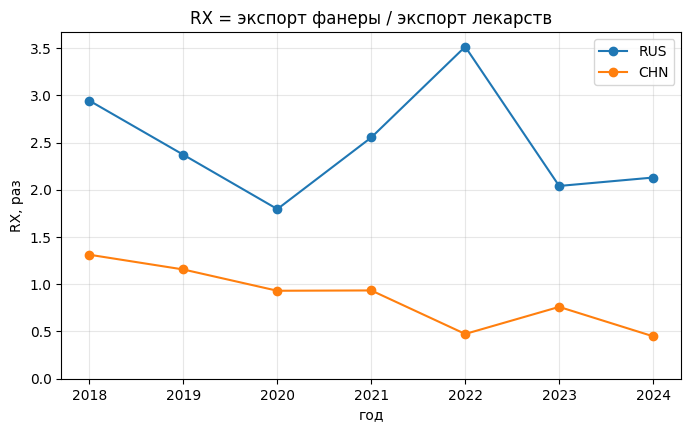

Лет с RX_RUS > RX_CHN: 7 из 7


In [4]:
rx_by_year = exports.pivot(index="year", columns="iso3", values="RX")[COMPARISON_ISO]
display(rx_by_year)

fig, ax = plt.subplots(figsize=(8, 4.5))
for iso in COMPARISON_ISO:
    ax.plot(rx_by_year.index, rx_by_year[iso], marker="o", label=iso)
ax.set_title("RX = экспорт фанеры / экспорт лекарств")
ax.set_xlabel("год")
ax.set_ylabel("RX, раз")
ax.set_ylim(0, None)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

years_rus_higher = (rx_by_year["RUS"] > rx_by_year[COMPARISON_ISO[1]]).sum()
print(f"Лет с RX_RUS > RX_{COMPARISON_ISO[1]}: {years_rus_higher} из {len(rx_by_year)}")

**Что видим.** RX России выше китайского во все 7 лет, с 2018 по 2024 год. Сами значения гуляют: у России от 1,80 в 2020 году до 3,51 в 2022-м, а у Китая RX почти всё время снижается, с 1,31 до 0,45, то есть лекарства в его экспорте набирают вес относительно фанеры. Устойчив порядок стран, а не величина разрыва.

## **[Синий, 2 балла, Красный, 2 балла]** Техническое задание 2. Факторная обеспеченность и чистый экспорт

### **[Синий, 1 балл]** Пункт 2а. Нормированный чистый экспорт

Используй `trade_p` и `factor_latest`, полученные в задании 1. Выбери последний год торговли и самостоятельно рассчитай для каждой страны

$$
NEX_i=\frac{X_i-M_i}{X_i+M_i}.
$$

Присоедини последний факторный показатель по ISO3 методом `merge()` и оставь страны из `SAMPLE_ISO`. Проверь, что все значения $NEX$ лежат между $-1$ и $1$. Источник и код факторного показателя уже сохранены в переменных первой ячейки.

**Исследовательский смысл.** $NEX$ сопоставляет экспорт и импорт товара с учётом общего масштаба торговли. Положительное значение указывает на преобладание экспорта, а отрицательное — импорта. Показатель не равен объёму выпуска и не измеряет внутреннее потребление.

**Что получить на выходе.** таблицу по странам с экспортом, импортом, $NEX$, факторным показателем и годами наблюдений.

**Пример вывода.**

| ISO3 | $X$ | $M$ | $NEX$ | фактор | год фактора |
|---|---:|---:|---:|---:|---:|
| [страна] | [экспорт] | [импорт] | [значение] | [значение] | [год] |

In [5]:
last_year = trade_p["year"].max()
nex_all = trade_p[trade_p["year"] == last_year].copy()
nex_all["NEX"] = (nex_all["export"] - nex_all["import"]) / (nex_all["export"] + nex_all["import"])

sample = nex_all.merge(factor_latest[["iso3", "factor", "factor_year"]], on="iso3")
sample = sample[sample["iso3"].isin(SAMPLE_ISO)].copy()
sample["X, млн долл."] = sample["export"] / 1e6
sample["M, млн долл."] = sample["import"] / 1e6

missing = sorted(set(SAMPLE_ISO) - set(sample["iso3"]))
print(f"Год торговли: {last_year}, стран в выборке: {len(sample)}, не нашлось: {missing if missing else 'нет'}")
print(f"Все NEX в границах [-1; 1]: {sample['NEX'].between(-1, 1).all()}")
print(f"Фактор: {FACTOR_NAME}, WDI {FACTOR_INDICATOR} / {POPULATION_INDICATOR}, годы {sample['factor_year'].min()}–{sample['factor_year'].max()}")

display(sample[["iso3", "country", "X, млн долл.", "M, млн долл.", "NEX", "factor", "factor_year"]])

rus = sample[sample["iso3"] == "RUS"].iloc[0]
print(f"Россия, {last_year}: X = {rus['X, млн долл.']:.1f} млн долл., M = {rus['M, млн долл.']:.1f} млн долл., NEX = {rus['NEX']:.3f}")

Год торговли: 2024, стран в выборке: 17, не нашлось: нет
Все NEX в границах [-1; 1]: True
Фактор: Площадь лесов на одного жителя, га на человека, WDI AG.LND.FRST.K2 / SP.POP.TOTL, годы 2024–2024


,iso3,country,"X, млн долл.","M, млн долл.",NEX,factor,factor_year
26,BRA,Brazil,845.228,8.235,0.981,2.308,2024
34,CHL,Chile,440.570,27.758,0.881,0.919,2024
35,CHN,China,"4,642.942",282.917,0.885,0.160,2024
49,DEU,Germany,304.567,968.509,-0.522,0.137,2024
56,EGY,Egypt,11.369,195.931,-0.890,0.000,2024
61,FIN,Finland,610.934,42.722,0.869,4.011,2024
66,GBR,United Kingdom,40.447,662.014,-0.885,0.047,2024
84,IDN,Indonesia,"1,772.418",31.714,0.965,0.338,2024
85,IND,India,61.947,257.590,-0.612,0.050,2024
94,JPN,Japan,50.541,"1,124.236",-0.914,0.201,2024


Россия, 2024: X = 730.9 млн долл., M = 8.9 млн долл., NEX = 0.976


**Что видим.** У России в 2024 году X = 730,9 млн долл., M = 8,9 млн долл., NEX = 0,976: фанеру мы почти только вывозим. NEX по построению лежит от −1 (только импорт) до 1 (только экспорт), проверка это подтверждает. Лес на человека у всех стран взят за 2024 год, тот же год, что и торговля. Ожидание модели: чем больше леса на человека, тем чаще NEX > 0.

### **[Синий, 1 балл]** Пункт 2б. Диаграмма факторной обеспеченности и торговли

Отсортируй `sample` по факторному показателю. Построй диаграмму рассеяния. По оси $x$ отложи факторный показатель, по оси $y$ — $NEX$. Подпиши страны и проведи горизонтальную линию $NEX=0$. Для графика можно использовать `plot.scatter()`, `annotate()` и `axhline()`.

**Исследовательский смысл.** Диаграмма показывает, согласуется ли знак чистого экспорта с простым факторным ожиданием в выбранной группе стран. Точки отражают страны, а не совместное предложение товаров и не равновесие спроса и предложения.

**Что получить на выходе.** отсортированную таблицу и читаемый подписанный график. В письменной части опиши общий рисунок и выбери две страны, которые в него не вписываются.

**Пример вывода.**

| ISO3 | фактор | $NEX$ | положение относительно ожидания |
|---|---:|---:|---|
| [страна] | [значение] | [значение] | согласуется / не согласуется |

,iso3,factor,NEX,положение относительно ожидания
0,RUS,5.790,0.976,согласуется
1,FIN,4.011,0.869,согласуется
2,BRA,2.308,0.981,согласуется
3,LVA,1.854,0.833,согласуется
4,CHL,0.919,0.881,согласуется
5,USA,0.909,-0.845,не согласуется
6,MYS,0.533,0.225,согласуется
7,IDN,0.338,0.965,согласуется
8,JPN,0.201,-0.914,согласуется
9,CHN,0.160,0.885,не согласуется


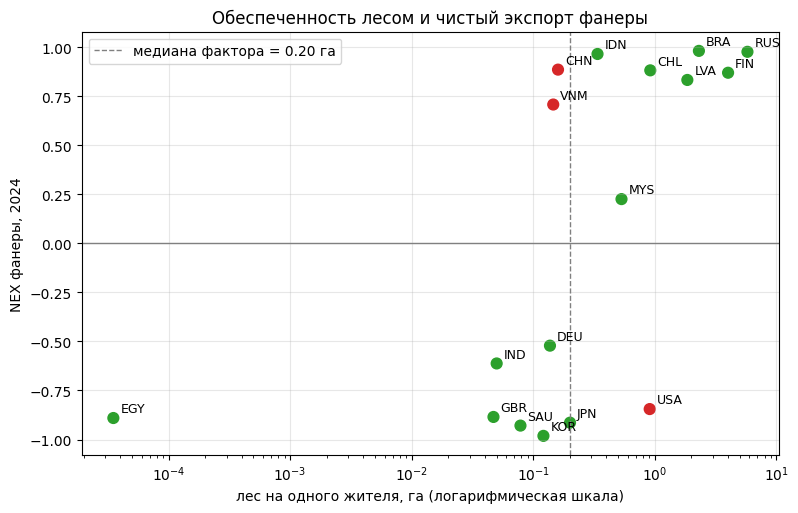

Зелёные точки согласуются с простым ожиданием, красные — нет


In [6]:
sample = sample.sort_values("factor", ascending=False).reset_index(drop=True)
factor_median = sample["factor"].median()

# Простое ожидание факторной модели: страны выше медианы по лесу — чистые экспортёры (NEX > 0),
# остальные — чистые импортёры (NEX < 0). Страна ровно на медиане попадает во вторую группу.
high_factor = sample["factor"] > factor_median
fits = (high_factor & (sample["NEX"] > 0)) | (~high_factor & (sample["NEX"] < 0))
sample["положение относительно ожидания"] = np.where(fits, "согласуется", "не согласуется")
display(sample[["iso3", "factor", "NEX", "положение относительно ожидания"]])

fig, ax = plt.subplots(figsize=(9, 5.5))
colors = np.where(fits, "tab:green", "tab:red")
ax.scatter(sample["factor"], sample["NEX"], c=colors, s=60)
for _, row in sample.iterrows():
    ax.annotate(row["iso3"], (row["factor"], row["NEX"]), textcoords="offset points", xytext=(5, 4), fontsize=9)
ax.axhline(0, color="gray", linewidth=1)
ax.axvline(factor_median, color="gray", linestyle="--", linewidth=1, label=f"медиана фактора = {factor_median:.2f} га")
ax.set_xscale("log")  # лес на человека отличается в тысячи раз, на обычной шкале все точки слипнутся
ax.set_xlabel("лес на одного жителя, га (логарифмическая шкала)")
ax.set_ylabel(f"NEX фанеры, {last_year}")
ax.set_title("Обеспеченность лесом и чистый экспорт фанеры")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
plt.show()
print("Зелёные точки согласуются с простым ожиданием, красные — нет")

**Что видим.** Справа вверху лесные страны с NEX около 1: Россия, Финляндия, Бразилия, Латвия, Чили. Слева внизу страны почти без леса на человека и с сильным чистым импортом: Египет, Великобритания, Индия, Саудовская Аравия, Корея. Не укладываются в картину США (0,91 га леса на человека, но NEX = −0,84) и Китай с Вьетнамом (меньше 0,2 га, но NEX 0,89 и 0,71). Япония стоит ровно на медиане и сама её задаёт.

### **[Красный, 1 балл]** Пункт 2в. Результат для выборки в целом

Найди медиану факторного показателя и раздели страны на две группы: с высоким и низким значением фактора. Для каждой группы самостоятельно рассчитай

$$
s_g=\frac{\text{число стран с }NEX>0}{\text{число стран в группе }g}.
$$

Выведи таблицу групп, медиану и список исключений. Исключением считай страну с высоким факторным показателем и отрицательным $NEX$ либо с низким факторным показателем и положительным $NEX$. Для группировки можно использовать `median()`, `np.where()` и `groupby().agg()`.

**Исследовательский смысл.** Доли $s_g$ проверяют, чаще ли страны с большей обеспеченностью фактором являются чистыми экспортёрами товара. Деление по медиане удобно для учебного расчёта, но зависит от состава небольшой выборки.

**Что получить на выходе.** медиану показателя, таблицу двух групп с долями чистых экспортёров и список исключений.

**Пример вывода.**

| группа | стран | доля чистых экспортёров |
|---|---:|---:|
| высокий фактор | [число] | [доля] |
| низкий фактор | [число] | [доля] |

| ISO3 | фактор | $NEX$ | тип исключения |
|---|---:|---:|---|
| [страна] | [значение] | [значение] | высокий фактор / низкий фактор |

In [7]:
sample["группа"] = np.where(high_factor, "высокий фактор", "низкий фактор")
sample["чистый экспортёр"] = sample["NEX"] > 0

groups = sample.groupby("группа").agg(
    стран=("iso3", "count"),
    чистых_экспортёров=("чистый экспортёр", "sum"),
)
groups["доля чистых экспортёров"] = groups["чистых_экспортёров"] / groups["стран"]

median_country = sample.loc[sample["factor"] == factor_median, "iso3"].tolist()
print(f"Медиана фактора: {factor_median:.3f} га на человека (на медиане: {median_country}, считаем в низкой группе)")
display(groups)

high_but_import = (sample["группа"] == "высокий фактор") & (sample["NEX"] < 0)
low_but_export = (sample["группа"] == "низкий фактор") & (sample["NEX"] > 0)
exceptions = sample[high_but_import | low_but_export].copy()
exceptions["тип исключения"] = np.where(exceptions["группа"] == "высокий фактор",
                                        "высокий фактор, чистый импорт", "низкий фактор, чистый экспорт")
display(exceptions[["iso3", "factor", "NEX", "тип исключения"]])

Медиана фактора: 0.201 га на человека (на медиане: ['JPN'], считаем в низкой группе)


,стран,чистых_экспортёров,доля чистых экспортёров
группа,,,
высокий фактор,8,7,0.875
низкий фактор,9,2,0.222


,iso3,factor,NEX,тип исключения
5,USA,0.909,-0.845,"высокий фактор, чистый импорт"
9,CHN,0.160,0.885,"низкий фактор, чистый экспорт"
10,VNM,0.146,0.707,"низкий фактор, чистый экспорт"


**Что видим.** В группе выше медианы (0,20 га на человека) чистые экспортёры — 7 стран из 8, доля 0,875. В группе ниже медианы — 2 из 9, доля 0,222. Общий порядок согласуется с факторной гипотезой, но исключения есть: США, Китай и Вьетнам. Медиана в выборке из 17 стран зависит от того, какие страны мы взяли, так что это проверка грубого порядка, не больше.

### **[Красный, 1 балл]** Пункт 2г. Исключения при заметном торговом обороте

Крайнее значение $NEX$ может возникнуть при очень маленьких потоках. Рассчитай торговый оборот товара $T_i=X_i+M_i$. Оставь страны с оборотом не ниже медианы и снова найди исключения из факторного ожидания. Сравни полученный список с `exceptions` из пункта 2в.

**Исследовательский смысл.** Фильтр по обороту отделяет заметные торговые связи от крайних отношений, полученных на малых значениях. Сохранившееся исключение требует содержательного объяснения, но ещё не является парадоксом Леонтьева: для такого вывода нужно оценить факторное содержание экспорта и импорта.

**Что получить на выходе.** медиану оборота и таблицу исключений, которые сохраняются среди стран с заметной торговлей.

**Пример вывода.**

```text
Медиана торгового оборота: [значение]
```

| ISO3 | оборот | фактор | $NEX$ |
|---|---:|---:|---:|
| [страна] | [значение] | [значение] | [значение] |

In [8]:
sample["оборот, млн долл."] = (sample["export"] + sample["import"]) / 1e6
turnover_median = sample["оборот, млн долл."].median()
print(f"Медиана торгового оборота: {turnover_median:,.1f} млн долл.")

big_traders = sample[sample["оборот, млн долл."] >= turnover_median]
big_high_import = (big_traders["группа"] == "высокий фактор") & (big_traders["NEX"] < 0)
big_low_export = (big_traders["группа"] == "низкий фактор") & (big_traders["NEX"] > 0)
stable_exceptions = big_traders[big_high_import | big_low_export]
display(stable_exceptions[["iso3", "оборот, млн долл.", "factor", "NEX"]])

dropped = sorted(set(exceptions["iso3"]) - set(stable_exceptions["iso3"]))
print(f"Исключений до фильтра: {len(exceptions)}, после: {len(stable_exceptions)}")
print(f"Выпали из-за малого оборота: {dropped if dropped else 'никто'}")

Медиана торгового оборота: 739.8 млн долл.


,iso3,"оборот, млн долл.",factor,NEX
5,USA,"3,346.403",0.909,-0.845
9,CHN,"4,925.859",0.160,0.885
10,VNM,"1,457.327",0.146,0.707


Исключений до фильтра: 3, после: 3
Выпали из-за малого оборота: никто


**Что видим.** Медиана оборота — 739,8 млн долл. Все три исключения остаются и после фильтра, причём это одни из самых крупных торговцев фанерой в выборке: оборот Китая 4,9 млрд долл., США 3,3 млрд, Вьетнама 1,5 млрд. Значит, дело не в маленьких потоках, на которых NEX легко уходит в крайние значения. Почему так выходит, здесь не проверяли: варианты объяснений идут в отчёт как гипотезы.

## **[Чёрный, 3 балла + 1 бонусный балл]** Техническое задание 3. Сопоставление импортных рынков и итог для PDF-отчёта

### **[Чёрный, 1 балл]** Пункт 3а. Сопоставление импортных рынков

Выбери шесть стран и запиши их в `MARKET_ISO`. Включи не менее двух крупных импортёров, двух стран с заметным ростом импорта и две страны с различной факторной обеспеченностью или разным знаком $NEX$. Категории могут пересекаться. Используй 2021 год и последний год панели:

$$
g_i=\left(\frac{M_{i,t_1}}{M_{i,t_0}}-1\right)\cdot100\%.
$$

Сам выбери строки двух лет, переименуй столбцы методом `rename()`, соедини таблицы через `merge()` и рассчитай $g_i$. Переведи импорт в миллиарды долларов.

**Исследовательский смысл.** Масштаб импорта, его изменение, $NEX$ и факторная обеспеченность отвечают на разные вопросы. Их нужно сопоставлять, а не складывать в готовый рейтинг перспективности.

**Пример вывода.**

| ISO3 | импорт 2021 | импорт последнего года | изменение, % | $NEX$ | фактор |
|---|---:|---:|---:|---:|---:|
| [страна] | [млрд долл.] | [млрд долл.] | [темп] | [значение] | [значение] |

In [9]:
first_year = 2021
imports_first = trade_p[trade_p["year"] == first_year][["iso3", "import"]].rename(columns={"import": "import_first"})
imports_last = trade_p[trade_p["year"] == last_year][["iso3", "country", "import"]].rename(columns={"import": "import_last"})

markets = imports_last.merge(imports_first, on="iso3")
markets = markets[markets["iso3"].isin(MARKET_ISO)]
markets = markets.merge(nex_all[["iso3", "NEX"]], on="iso3")
markets = markets.merge(factor_latest[["iso3", "factor"]], on="iso3")

markets[f"импорт {first_year}, млрд долл."] = markets["import_first"] / 1e9
markets[f"импорт {last_year}, млрд долл."] = markets["import_last"] / 1e9
markets["изменение, %"] = (markets["import_last"] / markets["import_first"] - 1) * 100
markets = markets.set_index("iso3").loc[MARKET_ISO].reset_index()

display(markets[["iso3", "country", f"импорт {first_year}, млрд долл.", f"импорт {last_year}, млрд долл.",
                 "изменение, %", "NEX", "factor"]])

,iso3,country,"импорт 2021, млрд долл.","импорт 2024, млрд долл.","изменение, %",NEX,factor
0,USA,United States,4.497,3.087,-31.363,-0.845,0.909
1,JPN,Japan,1.386,1.124,-18.879,-0.914,0.201
2,KOR,South Korea,0.880,0.689,-21.727,-0.981,0.121
3,IND,India,0.116,0.258,121.278,-0.612,0.050
4,SAU,Saudi Arabia,0.228,0.402,76.516,-0.929,0.079
5,EGY,Egypt,0.209,0.196,-6.221,-0.890,0.000


**Что видим.** Самый крупный импортёр — США, 3,09 млрд долл. в 2024 году, но к 2021 году их импорт сократился на 31%. Индия и Саудовская Аравия покупают намного меньше (0,26 и 0,40 млрд долл.), зато их импорт вырос на 121% и 77%. Все шесть стран — чистые импортёры фанеры, сильнее всех от ввоза зависит Корея (NEX = −0,98).

### **[Чёрный, 1 балл]** Пункт 3б. Места стран по трём показателям

Для каждой страны из `markets` рассчитай три места. Первое определяется импортом последнего года, второе — темпом его изменения, третье — импортной зависимостью. Для последнего показателя более отрицательный $NEX$ означает более высокое место. Используй метод `.rank()`.

**Исследовательский смысл.** Три места не нужно объединять в единственный балл. Большой рынок, быстро растущий рынок и импортозависимый рынок могут быть разными странами и требуют разных объяснений.

**Пример вывода.**

| ISO3 | место по импорту | место по росту | место по импортной зависимости |
|---|---:|---:|---:|
| [страна] | [место] | [место] | [место] |

In [10]:
places = markets[["iso3", "country"]].copy()
# 1 — лучшее место: самый большой импорт, самый быстрый рост, самый отрицательный NEX
places["место по импорту"] = markets["import_last"].rank(ascending=False, method="min").astype(int)
places["место по росту"] = markets["изменение, %"].rank(ascending=False, method="min").astype(int)
places["место по импортной зависимости"] = markets["NEX"].rank(ascending=True, method="min").astype(int)
display(places)
print("Места не складываем: большой, быстро растущий и зависимый от импорта рынок — разные вопросы")

,iso3,country,место по импорту,место по росту,место по импортной зависимости
0,USA,United States,1,6,5
1,JPN,Japan,2,4,3
2,KOR,South Korea,3,5,1
3,IND,India,5,1,6
4,SAU,Saudi Arabia,4,2,2
5,EGY,Egypt,6,3,4


Места не складываем: большой, быстро растущий и зависимый от импорта рынок — разные вопросы


**Что видим.** Первые места достались трём разным странам: по объёму импорта первые США, по росту Индия, по импортной зависимости Корея. Поэтому места и не складываем: каждая колонка отвечает на свой вопрос.

### **[Чёрный, 1 балл]** Пункт 3в. Прямое сопоставление двух стран

Выбери две страны из `markets` и запиши их коды в `CASE_ISO`. Выведи их строки и рассчитай разницу в импорте последнего года, темпе изменения импорта и $NEX$. Первой считай первую страну в `CASE_ISO`.

**Исследовательский смысл.** Парное сопоставление помогает сформулировать проверяемые гипотезы о различиях между рынками. Оно не должно превращаться в окончательный выбор страны без данных о барьерах, логистике, конкуренции и внутреннем спросе.

**Что получить на выходе.** две строки исходной таблицы и три разности, рассчитанные как «первая страна минус вторая». Эти значения должны без повторных расчётов переноситься в письменную часть.

**Пример вывода.**

| показатель | первая страна | вторая страна | разность |
|---|---:|---:|---:|
| импорт последнего года | [значение] | [значение] | [разность] |
| изменение импорта, % | [значение] | [значение] | [разность] |
| $NEX$ | [значение] | [значение] | [разность] |

In [11]:
CASE_ISO = ["KOR", "IND"]

case = markets.set_index("iso3").loc[CASE_ISO]
display(case[["country", f"импорт {last_year}, млрд долл.", "изменение, %", "NEX", "factor"]])

compare = pd.DataFrame({
    "показатель": [f"импорт {last_year}, млрд долл.", "изменение импорта, %", "NEX"],
    CASE_ISO[0]: [case.loc[CASE_ISO[0], f"импорт {last_year}, млрд долл."], case.loc[CASE_ISO[0], "изменение, %"], case.loc[CASE_ISO[0], "NEX"]],
    CASE_ISO[1]: [case.loc[CASE_ISO[1], f"импорт {last_year}, млрд долл."], case.loc[CASE_ISO[1], "изменение, %"], case.loc[CASE_ISO[1], "NEX"]],
})
compare["разность"] = compare[CASE_ISO[0]] - compare[CASE_ISO[1]]
display(compare)

,country,"импорт 2024, млрд долл.","изменение, %",NEX,factor
iso3,,,,,
KOR,South Korea,0.689,-21.727,-0.981,0.121
IND,India,0.258,121.278,-0.612,0.050


,показатель,KOR,IND,разность
0,"импорт 2024, млрд долл.",0.689,0.258,0.432
1,"изменение импорта, %",-21.727,121.278,-143.004
2,NEX,-0.981,-0.612,-0.369


**Что видим.** Корея ввозит фанеры на 0,43 млрд долл. больше Индии, но за 2021–2024 годы её импорт сократился на 22%, а индийский вырос на 121%, разница 143 процентных пункта. NEX у Кореи на 0,37 ниже: обратно она почти ничего не вывозит, а у Индии экспорт заметнее. Страны интересны по разным причинам, и это видно без общего рейтинга.

### **[Чёрный, 1 бонусный балл]** Пункт 3г. Публикации к выводам

Выбери один или несколько содержательных выводов из блокнота, которые твоя команда переносит в PDF-отчёт. Для каждого вывода найди одну или несколько надёжных публикаций, которые подтверждают определение показателя, единицы измерения, данные или важное ограничение вывода. Подойдут официальная статистика, методическое описание базы, документ международной организации, отраслевой материал или рецензируемая статья.

Укажи организацию или авторов, название, год или дату публикации, прямую ссылку и дату обращения. Коротко запиши, какой именно вывод поддерживает публикация и чего она не доказывает. Одной пары «вывод — публикация» достаточно для полного бонусного балла. Если хочешь, добавь ещё. Литературный обзор делать не нужно.

**Что должно получиться.** Таблица `source_check` из одной или нескольких строк. Каждая строка связывает один вывод с одной публикацией.

| вывод из блокнота | источник | ссылка | что подтверждает | чего не доказывает |
|---|---|---|---|---|
| [конкретный вывод] | [организация, название, дата] | https://... | [точная связь] | [граница источника] |

In [12]:
# Создай таблицу source_check из одной или нескольких строк.
# Сохрани прямую ссылку и точную связь источника с выводом.
russia_forest = factor_pair.loc[0, "factor"]
china_forest = factor_pair.loc[1, "factor"]

source_check = pd.DataFrame({
    "вывод из блокнота": [
        f"Леса на человека в России {russia_forest:.2f} га, в Китае {china_forest:.2f} га",
        "На 1 куб. м фанеры уходит 2,3–2,4 куб. м круглого леса, фанера лесоёмкая",
        "Исключения в пункте 2г ещё не парадокс Леонтьева",
    ],
    "источник": [
        "World Bank, World Development Indicators: Forest area (sq. km), AG.LND.FRST.K2, данные FAO",
        "FAO, ITTO, United Nations. Forest product conversion factors. Rome, 2020",
        "Leontief W. Domestic Production and Foreign Trade: The American Capital Position Re-Examined. "
        "Proceedings of the American Philosophical Society, 1953, 97(4), 332–349",
    ],
    "ссылка": [
        "https://data.worldbank.org/indicator/AG.LND.FRST.K2",
        "https://doi.org/10.4060/ca7952en",
        "https://www.jstor.org/stable/3149288",
    ],
    "дата обращения": ["17.10.2026", "17.10.2026", "17.10.2026"],
    "что подтверждает": [
        "Определение показателя и единицы: площадь земли под лесом в кв. км; на человека пересчитали сами",
        "Материальный баланс фанерного производства и расход круглого леса на кубометр продукции",
        "Леонтьев сравнивал факторное содержание экспорта и импортозамещающего производства США по таблицам «затраты — выпуск»",
    ],
    "чего не доказывает": [
        "Что весь этот лес доступен для заготовки и годится для фанеры",
        "Сколько гектаров земли приходится на доллар экспорта и какую роль играют труд и капитал",
        "Что наше расхождение по одному товару и одному фактору можно считать таким парадоксом",
    ],
})
display(source_check)

,вывод из блокнота,источник,ссылка,дата обращения,что подтверждает,чего не доказывает
0,"Леса на человека в России 5.79 га, в Китае 0.16 га","World Bank, World Development Indicators: Forest area (sq. km), AG.LND.FRST.K2, данные FAO",https://data.worldbank.org/indicator/AG.LND.FRST.K2,17.10.2026,Определение показателя и единицы: площадь земли под лесом в кв. км; на человека пересчитали сами,Что весь этот лес доступен для заготовки и годится для фанеры
1,"На 1 куб. м фанеры уходит 2,3–2,4 куб. м круглого леса, фанера лесоёмкая","FAO, ITTO, United Nations. Forest product conversion factors. Rome, 2020",https://doi.org/10.4060/ca7952en,17.10.2026,Материальный баланс фанерного производства и расход круглого леса на кубометр продукции,Сколько гектаров земли приходится на доллар экспорта и какую роль играют труд и капитал
2,Исключения в пункте 2г ещё не парадокс Леонтьева,Leontief W. Domestic Production and Foreign Trade: The American Capital Position Re-Examined. Proceedings of the Ame...,https://www.jstor.org/stable/3149288,17.10.2026,Леонтьев сравнивал факторное содержание экспорта и импортозамещающего производства США по таблицам «затраты — выпуск»,Что наше расхождение по одному товару и одному фактору можно считать таким парадоксом
